# Decision Tree Implementation

In [1]:
import numpy as np
import pandas as pd


## Cargar datos

In [2]:
PATH = "../data/titanic-machine-learning-from-disaster"

df = pd.read_csv(PATH + "/train.csv")

df.head(5)

"""
Vale mi matriz "X" serán las características necesarias para determinar supervivnecia
 
Y mi vector de chequeo "y" será la columna: Survived 
"""

'\nVale mi matriz "X" serán las características necesarias para determinar supervivnecia\n\nY mi vector de chequeo "y" será la columna: Survived \n'

### Normalizar Datos

In [3]:
df.columns = df.columns.str.lower()

strings = list(df.dtypes[df.dtypes == 'string'].index)

for col in strings:
    df[col] = df[col].str.lower().str.replace(' ', '_')

df.head()

,passengerid,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked
0,1,0,3,"braund,_mr._owen_harris",male,22.0,1,0,a/5_21171,7.2500,NaN,s
1,2,1,1,"cumings,_mrs._john_bradley_(florence_briggs_th...",female,38.0,1,0,pc_17599,71.2833,c85,c
2,3,1,3,"heikkinen,_miss._laina",female,26.0,0,0,ston/o2._3101282,7.9250,NaN,s
3,4,1,1,"futrelle,_mrs._jacques_heath_(lily_may_peel)",female,35.0,1,0,113803,53.1000,c123,s
4,5,0,3,"allen,_mr._william_henry",male,35.0,0,0,373450,8.0500,NaN,s


## Ánalisis Exploratorio de Datos

In [4]:
# Porcentaje de Hombres y Mujeres
supervivientes = df[df['survived'] == 1]
print(f"Total de SUpervivientes: {len(supervivientes)}, Total en el barco: {len(df)}")

supervivientes_mujeres = df[(df['survived'] == 1) & (df['sex'] == 'female')]
print("\n Supervivientes Mujeres: ", len(supervivientes_mujeres))

supervivientes_hombres = len(supervivientes) - len(supervivientes_mujeres)
print("\n Supervivientes Hombres: ", supervivientes_hombres)

porcentaje_sexo = supervivientes['sex'].value_counts(normalize=True) * 100
print("\nPorcentaje por sexo entre supervivientes:\n", porcentaje_sexo)

total_por_sexo = df['sex'].value_counts()
print("\nCantidad total de cada sexo en el barco:\n", total_por_sexo)

Total de SUpervivientes: 342, Total en el barco: 891

 Supervivientes Mujeres:  233

 Supervivientes Hombres:  109

Porcentaje por sexo entre supervivientes:
 sex
female    68.128655
male      31.871345
Name: proportion, dtype: float64

Cantidad total de cada sexo en el barco:
 sex
male      577
female    314
Name: count, dtype: int64


In [5]:
# Porcentaje por Rango de Edad entre Sobrevivientes

# Crear copia sin nulos
df_edad = df.dropna(subset=['age']).copy()

# Rangos de edad y las etiquetas
rangos = [0, 12, 19, 59, 100]
etiquetas = ['Niños', 'Adolescentes', 'Adultos', 'Ancianos']

df_edad['rango_edad'] = pd.cut(df_edad['age'], bins = rangos, labels=etiquetas)

# Filtrar por supervivientes
supervivientes_edad = df_edad[df_edad['survived'] == 1]

# Porcentaje
porcentaje_edad = supervivientes_edad['rango_edad'].value_counts(normalize=True) * 100
print("Porcentaje por rango de edad entre supervivientes:\n", porcentaje_edad)

Porcentaje por rango de edad entre supervivientes:
 rango_edad
Adultos         70.344828
Niños           13.793103
Adolescentes    13.448276
Ancianos         2.413793
Name: proportion, dtype: float64


In [6]:
# Importancia de Parch (Padres / Hijos)
print("--- Tasa de supervivencia según Parch (Padres/Hijos) ---")
parch_stats = df.groupby('parch')['survived'].agg(['count', 'mean'])
parch_stats['mean'] = parch_stats['mean'] * 100
print(parch_stats)

# Importancia de SibSp (Hermanos / Cónyugue)
print("\n--- Tasa de supervivencia según SibSp (Hermanos/Cónyuge) ---")
sibsp_stats = df.groupby('sibsp')['survived'].agg(['count', 'mean'])
parch_stats['mean'] = parch_stats['mean'] * 100
print(sibsp_stats)

--- Tasa de supervivencia según Parch (Padres/Hijos) ---
       count       mean
parch                  
0        678  34.365782
1        118  55.084746
2         80  50.000000
3          5  60.000000
4          4   0.000000
5          5  20.000000
6          1   0.000000

--- Tasa de supervivencia según SibSp (Hermanos/Cónyuge) ---
       count      mean
sibsp                 
0        608  0.345395
1        209  0.535885
2         28  0.464286
3         16  0.250000
4         18  0.166667
5          5  0.000000
8          7  0.000000


Las columnas que más información aportan a la hora de decidir quien sobrevive y quiern no es sin lugar a dudas (en mi opinión): edad y sexo.

Entonces vamos hacer un análisis más profundo de estas dos columnas

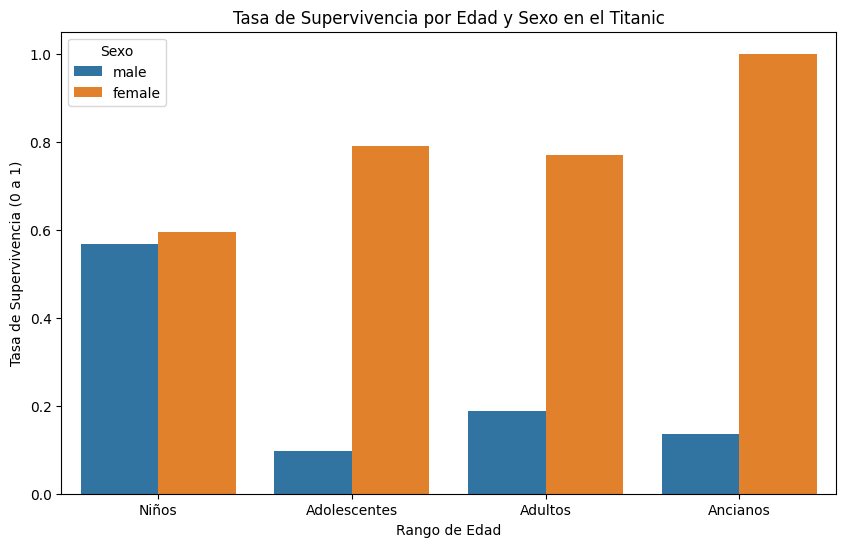

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

# Análisis cruzado: Sexo y Rango de EDAD

analisis_cruzado = df_edad.groupby(['sex', 'rango_edad'])['survived'].agg(
    Total = 'count',
    Sobrevivieron = 'sum').reset_index()

# Los que Fallecieron
analisis_cruzado['Fallecieron'] = analisis_cruzado['Total'] - analisis_cruzado['Sobrevivieron']

# Porcentaje de superviviencia de ese grupo ESPECÍFICO
analisis_cruzado['Tasa_Supervivencia_%'] = (analisis_cruzado['Sobrevivieron'] / analisis_cruzado['Total']) * 100

# Crear el gráfico
plt.figure(figsize=(10, 6))
sns.barplot(data=df_edad, x='rango_edad', y='survived', hue='sex', errorbar=None)

# Personalización
plt.title('Tasa de Supervivencia por Edad y Sexo en el Titanic')
plt.ylabel('Tasa de Supervivencia (0 a 1)')
plt.xlabel('Rango de Edad')
plt.legend(title='Sexo')
plt.show()

# Modelo 
# Árbol de Decisión

Primero vamos a extraer nuestra matriz **X** que tendra las columnas **sex** y **age**

Y también nuestro vector con el cual vamos a comparar y entrenar nuestro modelo, este vector es  **y** y contendrá los resultados de la columna **survived**

In [ ]:
df_modelo = df.copy()  # Copia de nuestro DataFrame original

df_modelo = df_modelo.dropna(subset=['age']) # eliminar valores nulos de 'age'ArithmeticError


# Vamos a codificar la columna sex (female: 1, male: 0)
df_modelo['sex'] = df_modelo['sex'].map({'female': 1, 'male': 0})

# Constrimos 'X' con las columnas 'sex' y 'age'
X = df_modelo[['sex', 'age']]

# Construir nuestro target
y = df_modelo['survived']
